# Project #2: Machine Learning Classification Model on F1 Reliability & Finish Status

**Objective:** Build a classification model to predict whether a driver will finish a Formula 1 race (Finish = 1) or experience a retirement / DNF (Finish = 0) based on historical race entries.

## Step 1: Problem Statement & Dataset Description
- **Dataset:** Ergast F1 Historical Database (`results.csv`, `status.csv`, `races.csv`, `constructors.csv`).
- **Target Variable:** `is_finished` (Binary classification: `1` if the driver finished the race, `0` if retired/DNF).
- **Prediction Goal:** Predict whether a starting driver will successfully finish a Grand Prix based on factors such as starting grid position, constructor, year, and circuit.

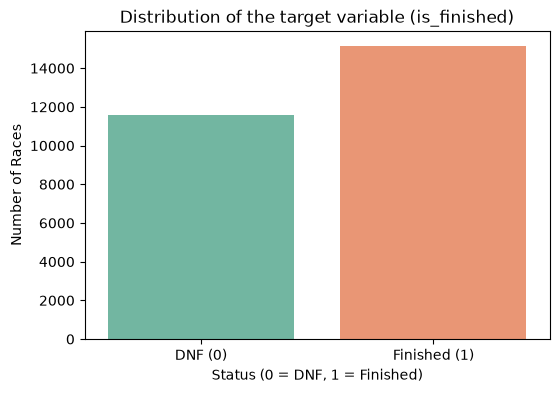

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

results = pd.read_csv('results.csv')
status = pd.read_csv('status.csv')
races = pd.read_csv('races.csv')
constructors = pd.read_csv('constructors.csv')

df = results.merge(status, on='statusId', how='left') \
            .merge(races[['raceId', 'year', 'circuitId']], on='raceId', how='left') \
            .merge(constructors[['constructorId', 'name']], on='constructorId', how='left', suffixes=('', '_constructor'))

df['is_finished'] = df['status'].str.contains(r'Finished|\+\d+ Lap', case=False, na=False).astype(int)

plt.figure(figsize=(6, 4))
sns.countplot(x='is_finished', hue='is_finished', data=df, palette='Set2', legend=False)
plt.title('Distribution of the target variable (is_finished)')
plt.xlabel('Status (0 = DNF, 1 = Finished)')
plt.ylabel('Number of Races')
plt.xticks([0, 1], ['DNF (0)', 'Finished (1)'])
plt.show()

This bar chart shows the distribution of the target variable is_finished. It helps visualize the total volume of race entries split between retirements/DNFs (0) and successfully finished races (1).

## Step 2: Basic Data Cleaning & Preprocessing
- Drop unwanted features.
- Handle missing values and duplicates.
- Convert non-numeric values to NaN and handle them.
- Outlier removal using boxplots/IQR for numeric variables (like grid).

Removed 488 duplicate rows.
The '0' position corresponds to starts from the pit lane.


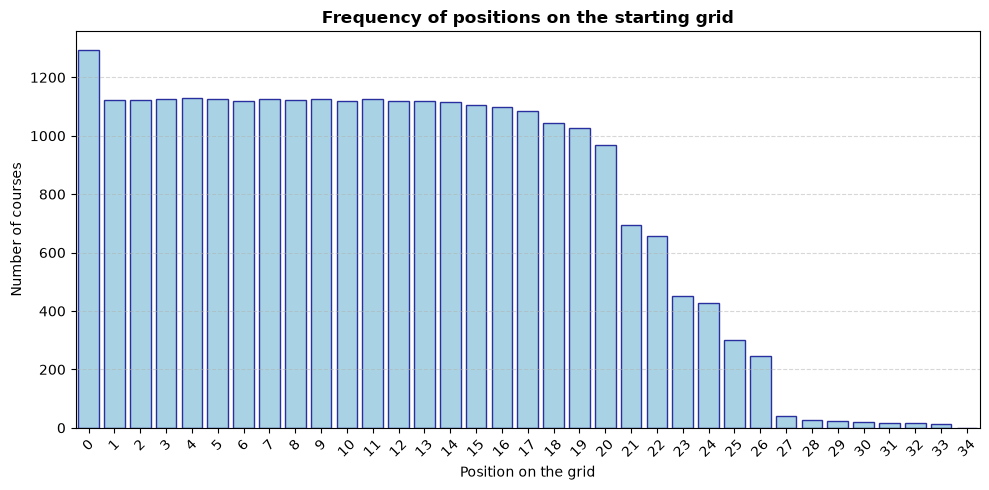

In [2]:
ml_df = df[['grid', 'year', 'circuitId', 'constructorId', 'is_finished']].copy()

ml_df = ml_df.replace(r'\\N', np.nan, regex=True)
ml_df = ml_df.dropna()

initial_len = len(ml_df)
ml_df = ml_df.drop_duplicates()
print(f"Removed {initial_len - len(ml_df)} duplicate rows.")

Q1 = ml_df['grid'].quantile(0.25)
Q3 = ml_df['grid'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

ml_df = ml_df[(ml_df['grid'] >= lower_bound) & (ml_df['grid'] <= upper_bound)]
print(f"The '0' position corresponds to starts from the pit lane.")
plt.figure(figsize=(10, 5))

ax = sns.countplot(
    x=ml_df["grid"], color="skyblue", edgecolor="darkblue", alpha=0.8
)

plt.title(
    "Frequency of positions on the starting grid",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Position on the grid", fontsize=10)
plt.ylabel("Number of courses", fontsize=10)

plt.xticks(rotation=45)

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

This graph illustrates the frequency of each starting grid position after data cleaning, duplicate removal, and outlier filtering using the Interquartile Range (IQR). It highlights that position 0 corresponds to starts from the pit lane.

## Step 3: Feature Engineering & Feature Selection
- Correlation analysis
- ANOVA F-test for numerical features
- Feature scaling

ANOVA F-test Results:
         Feature      F-value       p-value
0           grid    66.986965  2.855729e-16
1           year  2022.541908  0.000000e+00
2      circuitId     5.145911  2.330926e-02
3  constructorId     4.271662  3.876279e-02
Features scaled successfully using StandardScaler.


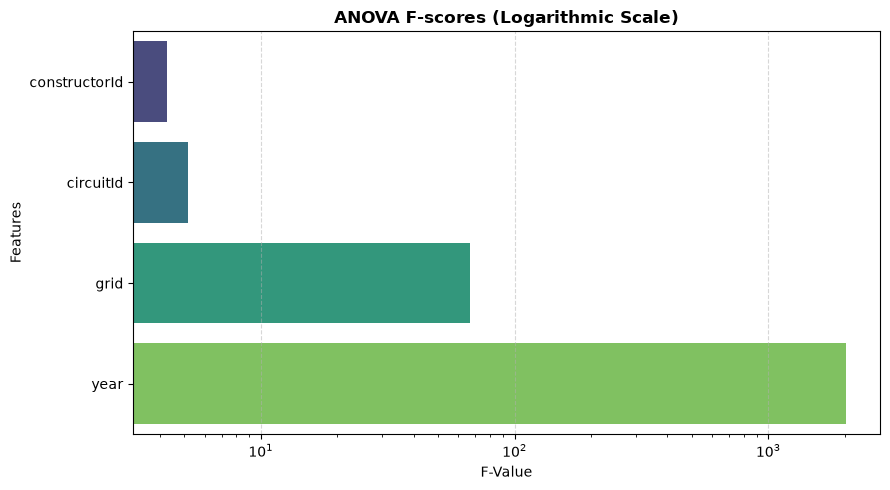

In [3]:
from sklearn.feature_selection import f_classif

X = ml_df[['grid', 'year', 'circuitId', 'constructorId']]
y = ml_df['is_finished']

f_values, p_values = f_classif(X, y)
anova_results = pd.DataFrame({'Feature': X.columns, 'F-value': f_values, 'p-value': p_values})
print("ANOVA F-test Results:")
print(anova_results)

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Features scaled successfully using StandardScaler.")

plt.figure(figsize=(9, 5))
plot_data = anova_results.sort_values(by="F-value", ascending=True)
ax = sns.barplot(
    x="F-value", y="Feature", data=plot_data, palette="viridis", hue="Feature", legend=False,
)
ax.set_xscale("log")

plt.title(
    "ANOVA F-scores (Logarithmic Scale)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("F-Value", fontsize=10)
plt.ylabel("Features", fontsize=10)
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

This chart displays the F-scores from the statistical ANOVA test on a logarithmic scale for the various features (grid, year, circuitId, constructorId). It helps evaluate the predictive power and relevance of each explanatory variable relative to the target.

## Step 4: Build & Train the Prediction Model
- Train/Test split
- Algorithm: Random Forest Classifier
- Evaluation metrics: Accuracy, Classification Report, Confusion Matrix

Model Accuracy: 62.72%

Classification Report:
              precision    recall  f1-score   support

           0       0.57      0.54      0.56      2267
           1       0.67      0.69      0.68      2988

    accuracy                           0.63      5255
   macro avg       0.62      0.62      0.62      5255
weighted avg       0.63      0.63      0.63      5255


Confusion Matrix:
[[1230 1037]
 [ 922 2066]]


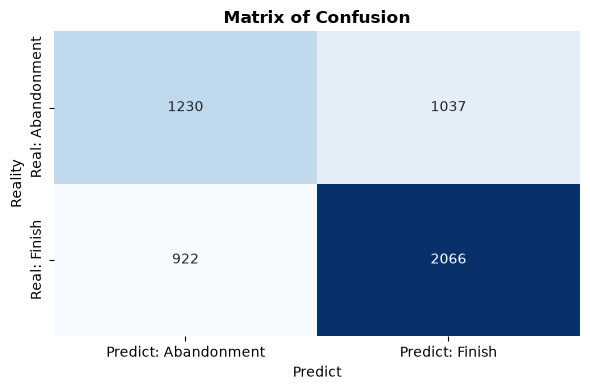

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

#changer le randomforestclassifier
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Predict: Abandonment", "Predict: Finish"],
    yticklabels=["Real: Abandonment", "Real: Finish"],
)

plt.title("Matrix of Confusion", fontsize=12, fontweight="bold")
plt.xlabel("Predict", fontsize=10)
plt.ylabel("Reality", fontsize=10)
plt.tight_layout()
plt.show()

This confusion matrix (displayed as a heatmap) evaluates the performance of the Random Forest classifier. It compares the model's predictions against the actual values, breaking down correct predictions and classification errors for both outcomes (retirement vs. finish).